In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())
print(df.head())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [3]:
y = df["resolution_hours"]

feature_columns = ["complexity_score", "team_experience_years"]
X = df[feature_columns]

print(X.shape, y.shape)   

(240, 2) (240,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)



In [5]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

mae  = mean_absolute_error(y_test, pred_base)                                                
rmse = np.sqrt(mean_squared_error(y_test, pred_base))
r2   = r2_score(y_test, pred_base)

print(mae, rmse, r2)

9.113951822916667 10.597684800766308 -0.021016765260001957


In [ ]:
def poly_pipe(degree):
    return make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

for d in (2, 3):
    res = cross_validate(
        poly_pipe(d), X_train, y_train, cv=cv,
        scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"),
        return_train_score=True
    )

In [11]:
from sklearn.model_selection import GridSearchCV

alphas = np.logspace(-3, 2, 26)   

ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": alphas}, cv=cv, scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

lasso = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=100000)),
    {"lasso__alpha": alphas}, cv=cv, scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)



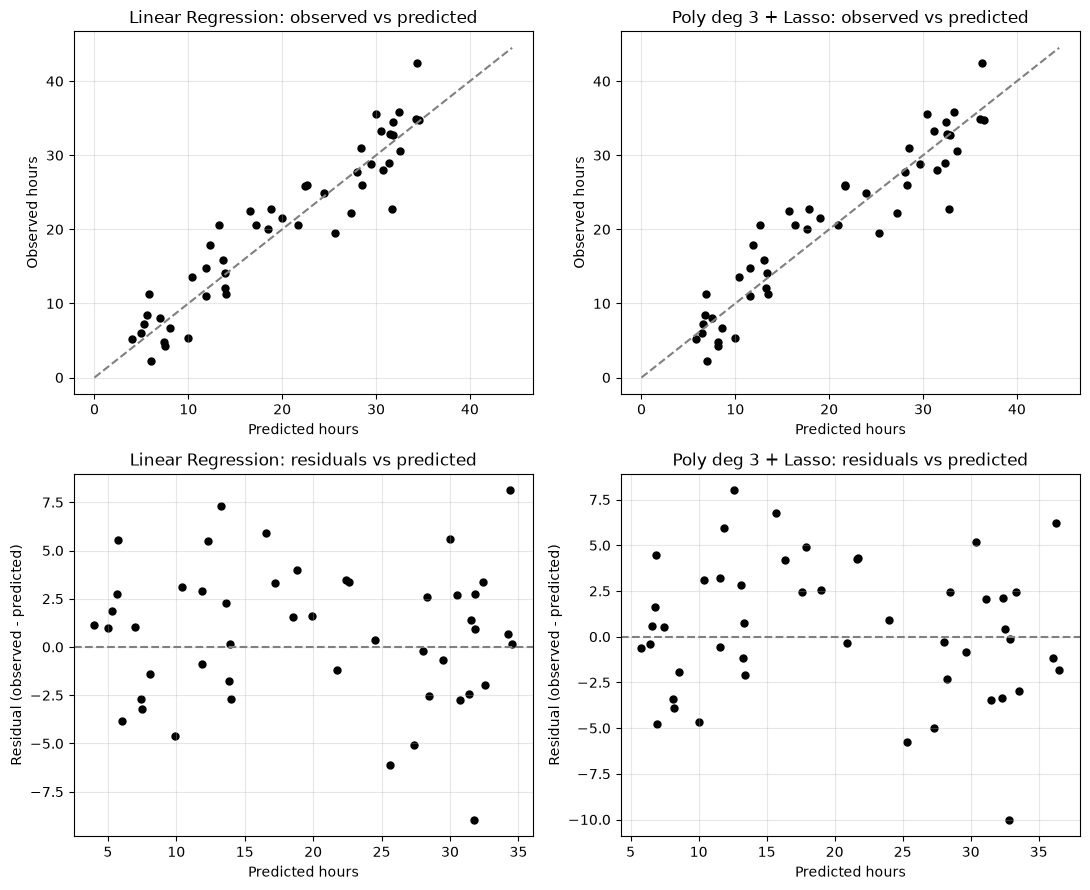

In [14]:
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Model 1: Linear Regression
lin = Pipeline([("scale", StandardScaler()),
                ("model", LinearRegression())]).fit(X_train, y_train)

# Model 2: Polynomial (degree 3) + Lasso, alpha chosen by CV on training set
poly_lasso = GridSearchCV(
    Pipeline([("poly", PolynomialFeatures(3, include_bias=False)),
              ("scale", StandardScaler()),
              ("model", Lasso(max_iter=100000))]),
    {"model__alpha": np.logspace(-3, 2, 26)},
    cv=cv, scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

models = {"Linear Regression": lin, "Poly deg 3 + Lasso": poly_lasso}

fig, axes = plt.subplots(2, 2, figsize=(11, 9), facecolor="white")

for col, (name, model) in enumerate(models.items()):
    pred = model.predict(X_test)
    resid = y_test.values - pred

    # Observed vs predicted
    ax = axes[0, col]
    ax.scatter(pred, y_test, color="black", s=25)
    lims = [0, max(pred.max(), y_test.max()) + 2]
    ax.plot(lims, lims, "--", color="gray")
    ax.set_title(f"{name}: observed vs predicted")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Observed hours")

    # Residuals vs predicted
    ax = axes[1, col]
    ax.scatter(pred, resid, color="black", s=25)
    ax.axhline(0, linestyle="--", color="gray")
    ax.set_title(f"{name}: residuals vs predicted")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Residual (observed - predicted)")

for ax in axes.ravel():
    ax.set_facecolor("white")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
def test_metrics(model):
    p = model.predict(X_test)
    return (mean_absolute_error(y_test, p),
            np.sqrt(mean_squared_error(y_test, p)),
            r2_score(y_test, p))

final_models = {
    "Mean baseline": baseline,
    "Linear Regression": lin,
    "Poly deg 3 + Lasso": poly_lasso,
}

summary = pd.DataFrame(
    {name: test_metrics(m) for name, m in final_models.items()},
    index=["MAE", "RMSE", "R2"]
).T.round(3)
print(summary)

                      MAE    RMSE     R2
Mean baseline       9.114  10.598 -0.021
Linear Regression   2.906   3.572  0.884
Poly deg 3 + Lasso  2.990   3.706  0.875
